# Student Academic Performance – Exploratory Data Analysis
**Dataset:** Students' Academic Performance Dataset (xAPI-Edu-Data), Kaggle `aljarah/xAPI-Edu-Data`.
**Target:** `Class` – `L` (Low), `M` (Middle), `H` (High) overall performance band.

> This notebook belongs to the **reconstructed Kaggle-based ML component**. It is separate from the original rule-based risk score (`1 - (0.6·marks + 0.4·attendance)`) in the existing application and was not part of the original SIH 2025 submission.

The raw CSV is only ever *read*; it is never modified.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
sns.set_theme(style="whitegrid", context="notebook")
df = pd.read_csv(ROOT / "dataset" / "raw" / "xAPI-Edu-Data.csv")
print("shape:", df.shape)
df.head()

shape: (480, 17)


  gender NationalITy  ... StudentAbsenceDays Class
0      M          KW  ...            Under-7     M
1      M          KW  ...            Under-7     M
2      M          KW  ...            Above-7     L
3      M          KW  ...            Above-7     L
4      M          KW  ...            Above-7     M

[5 rows x 17 columns]

## 1. Dataset overview, data types and columns

In [2]:
info = pd.DataFrame({"dtype": df.dtypes.astype(str), "n_unique": df.nunique(), "example": df.iloc[0]})
print(info.to_string())

                          dtype  n_unique     example
gender                      str         2           M
NationalITy                 str        14          KW
PlaceofBirth                str        14      KuwaIT
StageID                     str         3  lowerlevel
GradeID                     str        10        G-04
SectionID                   str         3           A
Topic                       str        12          IT
Semester                    str         2           F
Relation                    str         2      Father
raisedhands               int64        82          15
VisITedResources          int64        89          16
AnnouncementsView         int64        88           2
Discussion                int64        90          20
ParentAnsweringSurvey       str         2         Yes
ParentschoolSatisfaction    str         2        Good
StudentAbsenceDays          str         2     Under-7
Class                       str         3           M


## 2. Missing values and duplicates

In [3]:
print("Missing values per column:\n", df.isna().sum().to_string(), sep="")
print("\nTotal missing:", int(df.isna().sum().sum()))
dups = df[df.duplicated(keep=False)]
print("Exact duplicate rows (all copies shown):", len(dups))
print(dups.to_string())
print("Rows that are extra copies:", int(df.duplicated().sum()))

Missing values per column:
gender                      0
NationalITy                 0
PlaceofBirth                0
StageID                     0
GradeID                     0
SectionID                   0
Topic                       0
Semester                    0
Relation                    0
raisedhands                 0
VisITedResources            0
AnnouncementsView           0
Discussion                  0
ParentAnsweringSurvey       0
ParentschoolSatisfaction    0
StudentAbsenceDays          0
Class                       0

Total missing: 0
Exact duplicate rows (all copies shown): 4
    gender NationalITy PlaceofBirth     StageID GradeID SectionID   Topic Semester Relation  raisedhands  VisITedResources  AnnouncementsView  Discussion ParentAnsweringSurvey ParentschoolSatisfaction StudentAbsenceDays Class
322      M      Jordan       Jordan  lowerlevel    G-02         A  French        F   Father           10                15                 10          21                    No 

The data has **no missing values**, so no imputation is needed. There are only **2 extra exact-duplicate rows**. The file has no student ID, so they could be two genuinely different students with identical answers. The pipeline still drops them (in memory only) so a record can never appear in both the train and test sets.

## 3. Target distribution and class imbalance

       count  percent
Class                
L        127     26.5
M        211     44.0
H        142     29.6

Imbalance ratio (largest/smallest class): 1.66


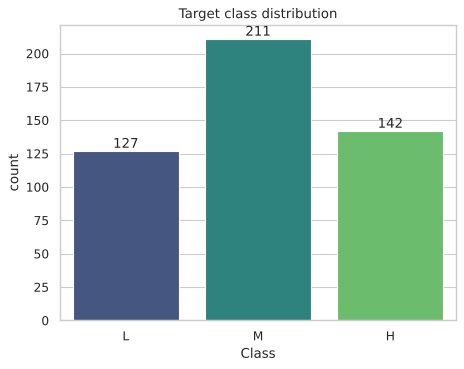

In [4]:
counts = df["Class"].value_counts().reindex(["L", "M", "H"])
share = (counts / counts.sum() * 100).round(1)
print(pd.DataFrame({"count": counts, "percent": share}).to_string())
print("\nImbalance ratio (largest/smallest class): %.2f" % (counts.max() / counts.min()))
ax = sns.countplot(data=df, x="Class", order=["L", "M", "H"], palette="viridis")
for p in ax.patches: ax.annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
ax.set_title("Target class distribution"); plt.show()

The classes are **mildly imbalanced** (Middle is the largest class, Low the smallest, ratio ≈ 1.7) – not severe enough to require resampling. We therefore use stratified splits and report macro-averaged metrics, and treat `class_weight='balanced'` as a tunable option rather than a default.

## 4. Descriptive statistics

In [5]:
num_cols = ["raisedhands", "VisITedResources", "AnnouncementsView", "Discussion"]
cat_cols = [c for c in df.columns if c not in num_cols + ["Class"]]
print(df[num_cols].describe().T.round(2).to_string())
print()
for c in cat_cols: print(f"{c:26s}", df[c].value_counts().to_dict())

                   count   mean    std  min    25%   50%   75%    max
raisedhands        480.0  46.78  30.78  0.0  15.75  50.0  75.0  100.0
VisITedResources   480.0  54.80  33.08  0.0  20.00  65.0  84.0   99.0
AnnouncementsView  480.0  37.92  26.61  0.0  14.00  33.0  58.0   98.0
Discussion         480.0  43.28  27.64  1.0  20.00  39.0  70.0   99.0

gender                     {'M': 305, 'F': 175}
NationalITy                {'KW': 179, 'Jordan': 172, 'Palestine': 28, 'Iraq': 22, 'lebanon': 17, 'Tunis': 12, 'SaudiArabia': 11, 'Egypt': 9, 'Syria': 7, 'USA': 6, 'Iran': 6, 'Lybia': 6, 'Morocco': 4, 'venzuela': 1}
PlaceofBirth               {'KuwaIT': 180, 'Jordan': 176, 'Iraq': 22, 'lebanon': 19, 'SaudiArabia': 16, 'USA': 16, 'Palestine': 10, 'Egypt': 9, 'Tunis': 9, 'Iran': 6, 'Syria': 6, 'Lybia': 6, 'Morocco': 4, 'venzuela': 1}
StageID                    {'MiddleSchool': 248, 'lowerlevel': 199, 'HighSchool': 33}
GradeID                    {'G-02': 147, 'G-08': 116, 'G-07': 101, 'G-04': 48, 

## 5. Numerical feature distributions

       raisedhands  VisITedResources  AnnouncementsView  Discussion
Class                                                              
L             16.9              18.3               15.6        30.8
M             48.9              60.6               41.0        43.8
H             70.3              78.7               53.4        53.7


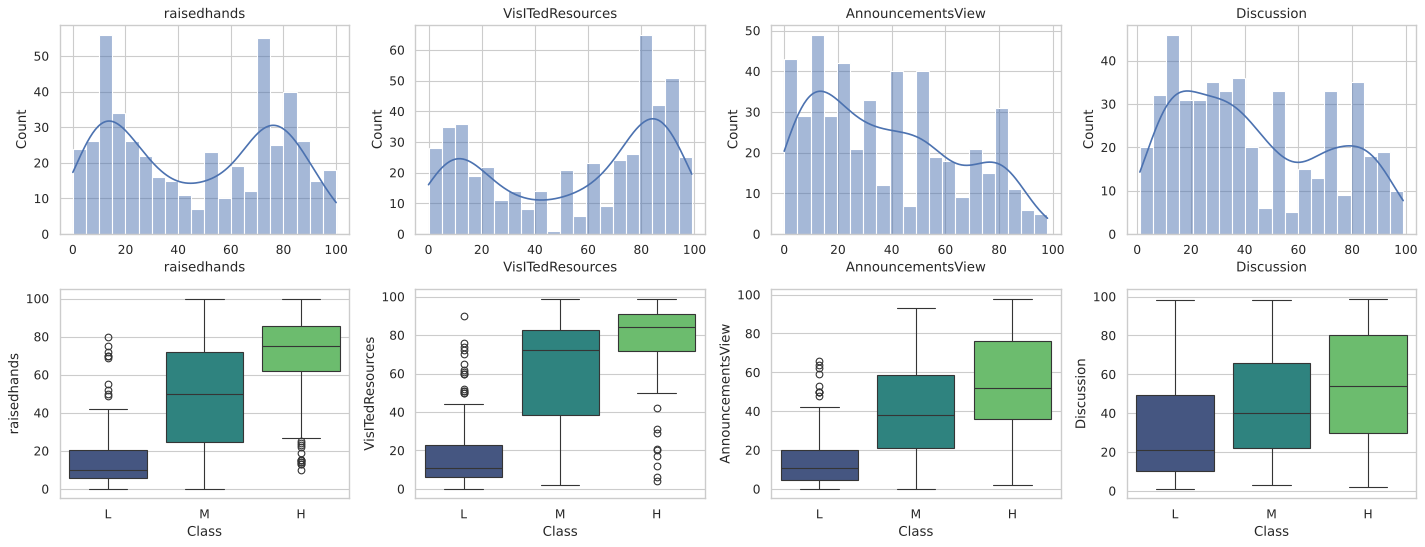

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for i, c in enumerate(num_cols):
    sns.histplot(df[c], bins=20, kde=True, ax=axes[0, i]); axes[0, i].set_title(c)
    sns.boxplot(data=df, x="Class", y=c, order=["L", "M", "H"], ax=axes[1, i], palette="viridis")
plt.tight_layout(); plt.show()
print(df.groupby("Class")[num_cols].mean().loc[["L", "M", "H"]].round(1).to_string())

All four engagement counters rise steadily from Low → Middle → High; `raisedhands` and `VisITedResources` separate the classes most clearly. `Discussion` separates them least.

## 6. Categorical feature distributions

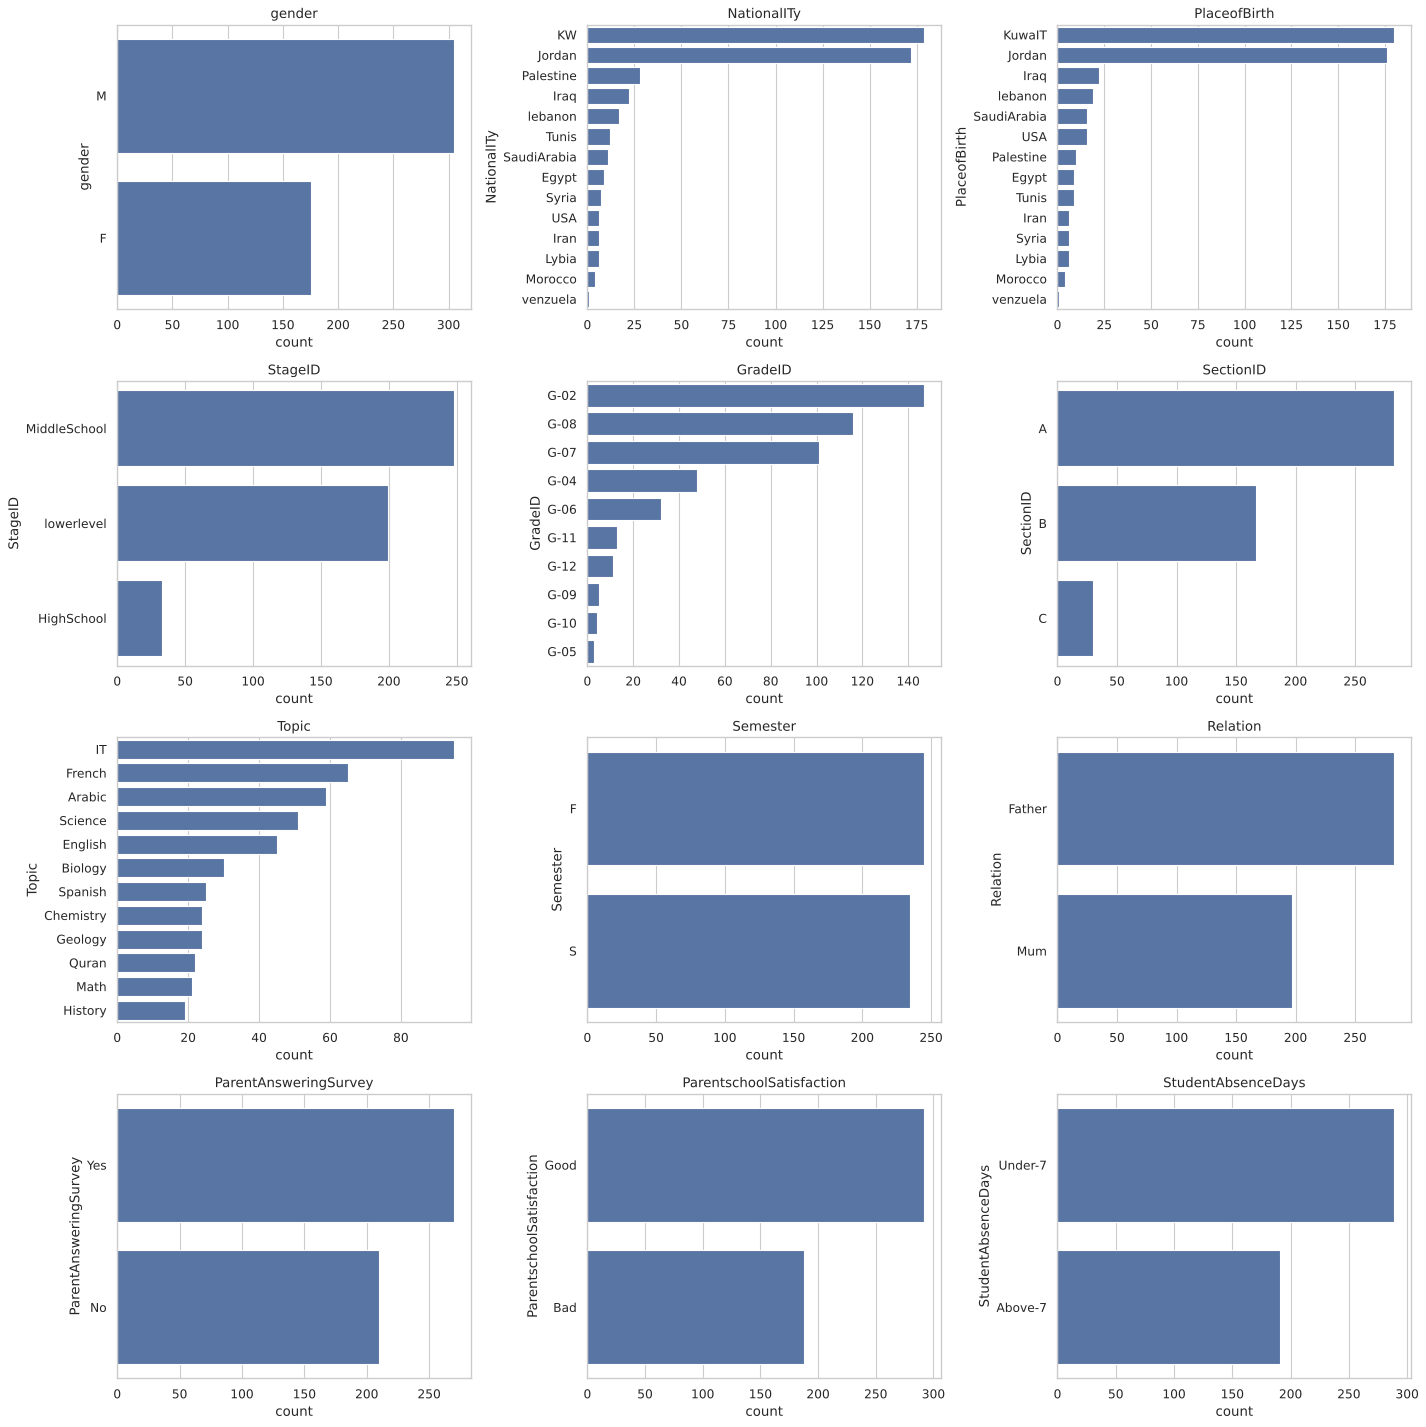

In [7]:
fig, axes = plt.subplots(4, 3, figsize=(18, 18))
for ax, c in zip(axes.ravel(), cat_cols):
    order = df[c].value_counts().index
    sns.countplot(data=df, y=c, order=order, ax=ax, color="#4C72B0"); ax.set_title(c)
plt.tight_layout(); plt.show()

## 7. Relationship between categorical features and performance

Class                 L    M    H
StudentAbsenceDays               
Above-7             116   71    4
Under-7              11  140  138

Class                  L     M     H
StudentAbsenceDays                  
Above-7             60.7  37.2   2.1
Under-7              3.8  48.4  47.8


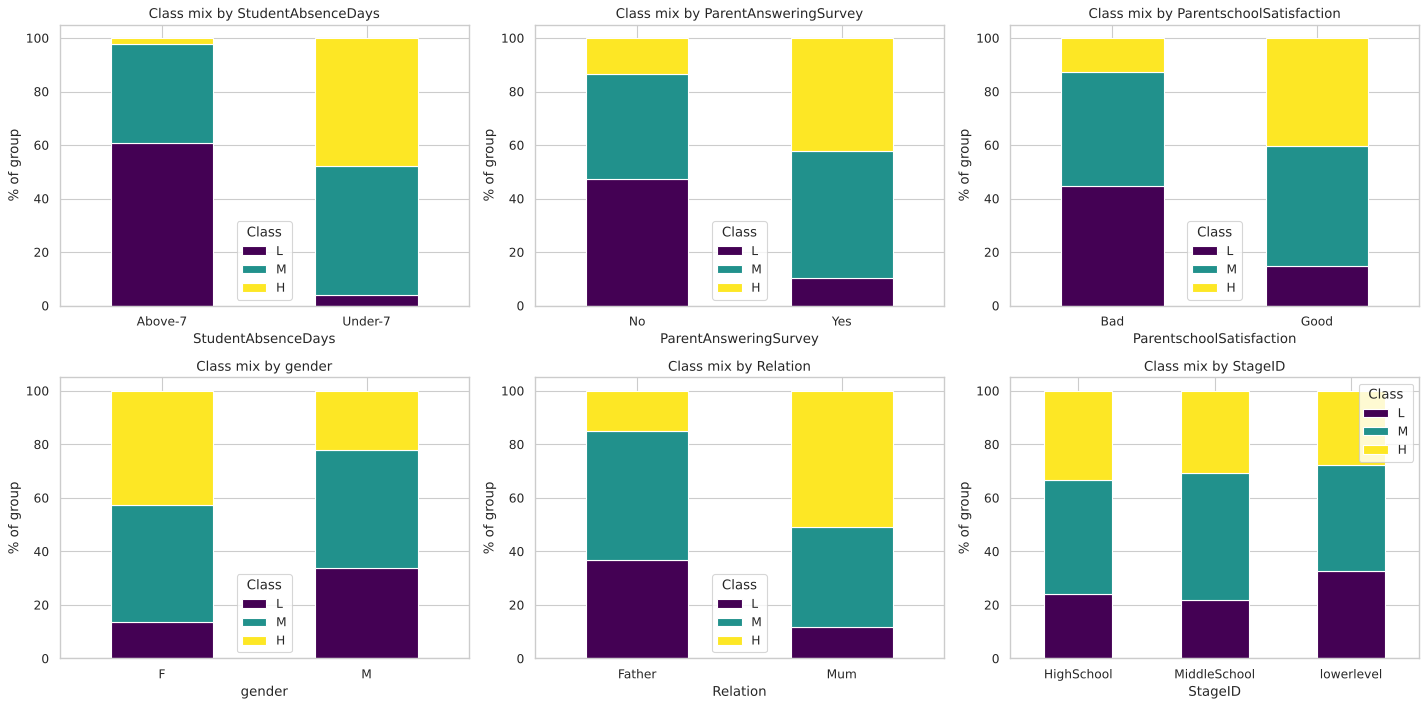

In [8]:
tab = pd.crosstab(df["StudentAbsenceDays"], df["Class"])[["L", "M", "H"]]
print(tab.to_string()); print()
print((tab.div(tab.sum(axis=1), axis=0) * 100).round(1).to_string())
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, c in zip(axes.ravel(), ["StudentAbsenceDays", "ParentAnsweringSurvey", "ParentschoolSatisfaction", "gender", "Relation", "StageID"]):
    pd.crosstab(df[c], df["Class"], normalize="index")[["L", "M", "H"]].mul(100).plot(kind="bar", stacked=True, ax=ax, colormap="viridis")
    ax.set_ylabel("% of group"); ax.set_title(f"Class mix by {c}"); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

In [9]:
from scipy.stats import chi2_contingency
rows = []
for c in cat_cols:
    ct = pd.crosstab(df[c], df["Class"]); chi2, p, dof, _ = chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    rows.append((c, round(v, 3), p))
assoc = pd.DataFrame(rows, columns=["feature", "cramers_v", "chi2_p_value"]).sort_values("cramers_v", ascending=False)
print(assoc.to_string(index=False))

                 feature  cramers_v  chi2_p_value
      StudentAbsenceDays      0.685  1.251396e-49
   ParentAnsweringSurvey      0.446  1.958076e-21
                Relation      0.412  2.146333e-18
ParentschoolSatisfaction      0.378  1.355293e-15
            PlaceofBirth      0.280  1.011826e-06
             NationalITy      0.277  1.802272e-06
                  gender      0.263  5.798288e-08
                   Topic      0.217  2.522267e-03
                 GradeID      0.174  4.821880e-02
                Semester      0.128  2.002399e-02
                 StageID      0.086  1.307500e-01
               SectionID      0.068  3.497926e-01


`StudentAbsenceDays` has by far the strongest association with `Class`: **116 of the 191 students with more than 7 absences are Low**, versus 11 of 289 with fewer. Parent survey participation (V≈0.45), `Relation` (Father/Mum, V≈0.41) and parent school satisfaction (V≈0.38) come next. The `Relation` association has no obvious causal story and probably reflects how the data was collected, so it is treated as a correlational artefact, not a lever. Note that the chi-square p-values for sparse categories (e.g. `NationalITy`, `PlaceofBirth`) are unreliable because some cells have very few students.

## 8. Correlation analysis

                   raisedhands  VisITedResources  AnnouncementsView  Discussion  Class_ordinal
raisedhands              1.000             0.662              0.653       0.338          0.649
VisITedResources         0.662             1.000              0.573       0.208          0.664
AnnouncementsView        0.653             0.573              1.000       0.402          0.546
Discussion               0.338             0.208              0.402       1.000          0.318
Class_ordinal            0.649             0.664              0.546       0.318          1.000


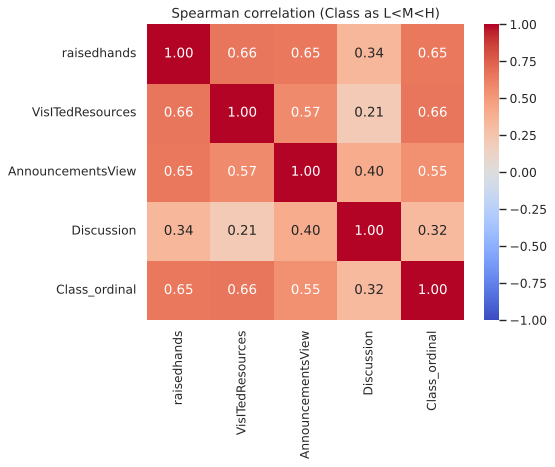

In [10]:
tmp = df[num_cols].copy(); tmp["Class_ordinal"] = df["Class"].map({"L": 0, "M": 1, "H": 2})
corr = tmp.corr(method="spearman")
print(corr.round(3).to_string())
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1); plt.title("Spearman correlation (Class as L<M<H)"); plt.show()

Spearman rank correlation is used because `Class` is ordinal. The four engagement counters are all positively correlated with the performance band and with each other (moderate multicollinearity), which is why tree models and regularised logistic regression are both reasonable choices.

## 9. Findings and implications for modelling

* 480 rows, 16 features + target, **no missing values**, 2 duplicate rows.
* Mild class imbalance → stratified splitting, macro-F1, and explicit attention to **recall of the Low class**.
* `StudentAbsenceDays` is the dominant predictor; engagement counters (`VisITedResources`, `raisedhands`) come next.
* Tree models need no scaling; only logistic regression gets standardised numerics.
* **Caveats:** the dataset is small (≈480 students from one e-learning platform), `Class` is a *performance band* label rather than a future-outcome label, and several features (resource visits, hand raises) do not exist in the existing attendance application. Results should not be read as validated for another institution.